In [1]:
# 1. Install required neuroscience & OpenNeuro download packages
!pip install -q openneuro-py mne antropy scipy numpy pandas openpyxl

import os
import glob
import mne
import numpy as np
import pandas as pd
import antropy as ant
import openneuro as on
from scipy import signal, stats

# 2. Download the first batch directly from OpenNeuro ds004504
# (participants.tsv + 5 Alzheimer's [sub-001 to sub-005] + 5 Healthy Controls [sub-037 to sub-041])
target_dir = "ds004504_batch1"
os.makedirs(target_dir, exist_ok=True)

batch_subjects = [
    "participants.tsv",
    "derivatives/sub-001", "derivatives/sub-002", "derivatives/sub-003", "derivatives/sub-004", "derivatives/sub-005",
    "derivatives/sub-037", "derivatives/sub-038", "derivatives/sub-039", "derivatives/sub-040", "derivatives/sub-041"
]

print("Downloading real preprocessed EEG files from OpenNeuro ds004504...")
on.download(dataset="ds004504", target_dir=target_dir, include=batch_subjects)

# 3. Load participant clinical labels (A = Alzheimer's, C = Healthy Control, F = FTD)
participants = pd.read_csv(os.path.join(target_dir, "participants.tsv"), sep="\t")
label_map = dict(zip(participants["participant_id"], participants["Group"]))
mmse_map = dict(zip(participants["participant_id"], participants["MMSE"]))

# 4. Compute the 4 NeuroCritix complexity & criticality metrics on each real EEG
def analyze_eeg_file(file_path):
    raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
    fs = raw.info['sfreq']

    # Extract a clean 60-second resting segment (30s to 90s)
    data = raw.get_data(tmin=30, tmax=90)

    shannon_list, lz_list, dfa_list, beta_list = [], [], [], []

    for ch_signal in data:
        # 1. Shannon / Spectral Entropy
        shannon_list.append(ant.spectral_entropy(ch_signal, sf=fs, method='welch', normalize=False))
        # 2. Lempel-Ziv Complexity (0 to 1)
        binary_seq = (ch_signal > np.median(ch_signal)).astype(int)
        lz_list.append(ant.lziv_complexity(binary_seq, normalize=True))
        # 3. Detrended Fluctuation Analysis (DFA)
        dfa_list.append(ant.detrended_fluctuation(ch_signal))
        # 4. 1/f Power-Law Scaling Exponent (Beta across 2-40 Hz)
        freqs, psd = signal.welch(ch_signal, fs=fs, nperseg=int(fs*2))
        valid = (freqs >= 2) & (freqs <= 40)
        slope, _, _, _, _ = stats.linregress(np.log10(freqs[valid]), np.log10(psd[valid]))
        beta_list.append(-slope)

    sub_id = os.path.basename(file_path).split('_')[0]
    group_code = label_map.get(sub_id, "Unknown")
    group_name = "Alzheimer's (AD)" if group_code == "A" else ("Healthy Control" if group_code == "C" else group_code)

    return {
        "Subject_ID": sub_id,
        "Group": group_name,
        "MMSE_Score": mmse_map.get(sub_id, None),
        "Shannon_Entropy": round(np.mean(shannon_list), 3),
        "LZ_Complexity": round(np.mean(lz_list), 3),
        "DFA_Exponent": round(np.mean(dfa_list), 3),
        "PowerLaw_Beta": round(np.mean(beta_list), 3)
    }

# 5. Run analysis on all 10 downloaded subjects
results = []
eeg_files = sorted(glob.glob(os.path.join(target_dir, "derivatives", "**", "*.set"), recursive=True))

print(f"\nFound {len(eeg_files)} EEG recordings. Running NeuroCritix analysis...\n")
for f in eeg_files:
    results.append(analyze_eeg_file(f))

df = pd.DataFrame(results)
print("=== INDIVIDUAL SUBJECT RESULTS ===")
print(df.to_string(index=False))

print("\n=== GROUP AVERAGES (HEALTHY VS. ALZHEIMER'S) ===")
print(df.groupby("Group")[["MMSE_Score", "Shannon_Entropy", "LZ_Complexity", "DFA_Exponent", "PowerLaw_Beta"]].mean().round(3))

# Save results to downloadable Excel & CSV files
df.to_excel("NeuroCritix_Batch1_Results.xlsx", index=False)
df.to_csv("NeuroCritix_Batch1_Results.csv", index=False)
print("\nSaved 'NeuroCritix_Batch1_Results.xlsx' in the Colab Files sidebar (left panel)!")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
🌍 Preparing to download ds004504 …
📥 Checking 15 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds004504 (downloaded 15 files and 302.2 MB).

Found 10 EEG recordings. Running NeuroCritix analysis...



/tmp/ipykernel_522/1071374313.py:34: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
/tmp/ipykernel_522/1071374313.py:34: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
/tmp/ipykernel_522/1071374313.py:34: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
/tmp/ipykernel_522/1071374313.py:34: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, ver

=== INDIVIDUAL SUBJECT RESULTS ===
Subject_ID            Group  MMSE_Score  Shannon_Entropy  LZ_Complexity  DFA_Exponent  PowerLaw_Beta
   sub-001 Alzheimer's (AD)          16            2.236          0.104         1.381          1.929
   sub-002 Alzheimer's (AD)          22            2.495          0.116         1.347          2.143
   sub-003 Alzheimer's (AD)          14            2.462          0.098         1.357          2.285
   sub-004 Alzheimer's (AD)          20            2.255          0.109         1.372          1.859
   sub-005 Alzheimer's (AD)          22            2.246          0.093         1.406          2.210
   sub-037  Healthy Control          30            2.454          0.104         1.362          2.303
   sub-038  Healthy Control          30            2.240          0.099         1.396          2.086
   sub-039  Healthy Control          30            2.707          0.129         1.316          2.194
   sub-040  Healthy Control          30            2.229

In [2]:
import os, glob, mne
import numpy as np
import pandas as pd
import antropy as ant
import openneuro as on
from scipy import signal, stats
from sklearn.metrics import roc_auc_score

# 1. Download 30 subjects total (15 AD: sub-001..015 | 15 Healthy: sub-037..051)
target_dir = "ds004504_30subjects"
os.makedirs(target_dir, exist_ok=True)

ad_subs = [f"derivatives/sub-{i:03d}" for i in range(1, 16)]
hc_subs = [f"derivatives/sub-{i:03d}" for i in range(37, 52)]
on.download(dataset="ds004504", target_dir=target_dir, include=["participants.tsv"] + ad_subs + hc_subs)

participants = pd.read_csv(os.path.join(target_dir, "participants.tsv"), sep="\t")
label_map = dict(zip(participants["participant_id"], participants["Group"]))
mmse_map = dict(zip(participants["participant_id"], participants["MMSE"]))

# Posterior & temporal channels most sensitive to early Alzheimer's network breakdown
target_channels = ['P3', 'P4', 'Pz', 'O1', 'O2', 'T5', 'T6']

def analyze_refined_eeg(file_path):
    raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
    fs = raw.info['sfreq']

    # Pick posterior/temporal channels if present
    picks = [ch for ch in target_channels if ch in raw.ch_names]
    raw.pick(picks)

    # Filter to Alpha-Beta cognitive band (8-30 Hz) for complexity & DFA
    raw_alpha_beta = raw.copy().filter(8.0, 30.0, verbose=False)
    data_ab = raw_alpha_beta.get_data(tmin=30, tmax=120)  # 90-second window
    data_broad = raw.get_data(tmin=30, tmax=120)

    shannon_list, lz_list, dfa_list, beta_list = [], [], [], []

    for idx in range(len(picks)):
        sig_ab = data_ab[idx]
        sig_br = data_broad[idx]

        # 1. Spectral Entropy (normalized 0-1 in 8-30 Hz band)
        shannon_list.append(ant.spectral_entropy(sig_ab, sf=fs, method='welch', normalize=True))
        # 2. Lempel-Ziv Complexity in cognitive band (8-30 Hz)
        binary_seq = (sig_ab > np.median(sig_ab)).astype(int)
        lz_list.append(ant.lziv_complexity(binary_seq, normalize=True))
        # 3. DFA on Alpha amplitude envelope (captures long-range critical dynamics!)
        analytic_signal = signal.hilbert(sig_ab)
        amplitude_envelope = np.abs(analytic_signal)
        dfa_list.append(ant.detrended_fluctuation(amplitude_envelope))
        # 4. 1/f Power-Law Slope (Beta across 2-40 Hz)
        freqs, psd = signal.welch(sig_br, fs=fs, nperseg=int(fs*2))
        valid = (freqs >= 2) & (freqs <= 40)
        slope, _, _, _, _ = stats.linregress(np.log10(freqs[valid]), np.log10(psd[valid]))
        beta_list.append(-slope)

    sub_id = os.path.basename(file_path).split('_')
    group_code = label_map.get(sub_id, "Unknown")

    return {
        "Subject_ID": sub_id,
        "Group": "Alzheimer's (AD)" if group_code == "A" else "Healthy Control",
        "Label_Num": 1 if group_code == "A" else 0,
        "MMSE": mmse_map.get(sub_id, None),
        "Shannon_Entropy": round(np.mean(shannon_list), 4),
        "LZ_Complexity": round(np.mean(lz_list), 4),
        "DFA_Envelope": round(np.mean(dfa_list), 4),
        "PowerLaw_Beta": round(np.mean(beta_list), 4)
    }

eeg_files = sorted(glob.glob(os.path.join(target_dir, "derivatives", "**", "*.set"), recursive=True))
df30 = pd.DataFrame([analyze_refined_eeg(f) for f in eeg_files])

print("=== 30-SUBJECT GROUP AVERAGES ===")
print(df30.groupby("Group")[["MMSE", "Shannon_Entropy", "LZ_Complexity", "DFA_Envelope", "PowerLaw_Beta"]].mean().round(4))

print("\n=== STATISTICAL SIGNIFICANCE (MANN-WHITNEY U TEST & ROC-AUC) ===")
ad_df = df30[df30["Label_Num"] == 1]
hc_df = df30[df30["Label_Num"] == 0]

for metric in ["Shannon_Entropy", "LZ_Complexity", "DFA_Envelope", "PowerLaw_Beta"]:
    stat, p_val = stats.mannwhitneyu(hc_df[metric], ad_df[metric])
    auc = roc_auc_score(df30["Label_Num"], -df30[metric])
    auc = max(auc, 1 - auc)  # Direction-independent AUC
    sig = "✅ SIGNIFICANT (p < 0.05)" if p_val < 0.05 else "⚠️ Trend only"
    print(f"{metric:18s} | p-value = {p_val:.4f} | ROC-AUC = {auc:.3f} | {sig}")

df30.to_excel("NeuroCritix_30Subjects_Validated.xlsx", index=False)


🌍 Preparing to download ds004504 …
📥 Checking 35 files, downloading as needed (5 concurrent downloads). 


Output()

🔄 Could not connect (DNS or network error) while downloading 
derivatives/sub-044/eeg/sub-044_task-eyesclosed_eeg.set, retrying (5 retries remain, backing off 0.5s) …

✅ Finished downloading ds004504 (downloaded 35 files and 982.9 MB).


TypeError: unhashable type: 'list'

In [3]:
import os, glob, mne
import numpy as np
import pandas as pd
import antropy as ant
from scipy import signal, stats
from sklearn.metrics import roc_auc_score

target_dir = "ds004504_30subjects"
participants = pd.read_csv(os.path.join(target_dir, "participants.tsv"), sep="\t")
label_map = dict(zip(participants["participant_id"], participants["Group"]))
mmse_map = dict(zip(participants["participant_id"], participants["MMSE"]))

target_channels = ['P3', 'P4', 'Pz', 'O1', 'O2', 'T5', 'T6']

def analyze_refined_eeg(file_path):
    raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
    fs = raw.info['sfreq']

    picks = [ch for ch in target_channels if ch in raw.ch_names]
    raw.pick(picks)

    raw_alpha_beta = raw.copy().filter(8.0, 30.0, verbose=False)
    data_ab = raw_alpha_beta.get_data(tmin=30, tmax=120)
    data_broad = raw.get_data(tmin=30, tmax=120)

    shannon_list, lz_list, dfa_list, beta_list = [], [], [], []

    for idx in range(len(picks)):
        sig_ab = data_ab[idx]
        sig_br = data_broad[idx]

        shannon_list.append(ant.spectral_entropy(sig_ab, sf=fs, method='welch', normalize=True))
        binary_seq = (sig_ab > np.median(sig_ab)).astype(int)
        lz_list.append(ant.lziv_complexity(binary_seq, normalize=True))

        analytic_signal = signal.hilbert(sig_ab)
        amplitude_envelope = np.abs(analytic_signal)
        dfa_list.append(ant.detrended_fluctuation(amplitude_envelope))

        freqs, psd = signal.welch(sig_br, fs=fs, nperseg=int(fs*2))
        valid = (freqs >= 2) & (freqs <= 40)
        slope, _, _, _, _ = stats.linregress(np.log10(freqs[valid]), np.log10(psd[valid]))
        beta_list.append(-slope)

    sub_id = os.path.basename(file_path).split('_')[0]
    group_code = label_map.get(sub_id, "Unknown")

    return {
        "Subject_ID": sub_id,
        "Group": "Alzheimer's (AD)" if group_code == "A" else "Healthy Control",
        "Label_Num": 1 if group_code == "A" else 0,
        "MMSE": mmse_map.get(sub_id, None),
        "Shannon_Entropy": round(np.mean(shannon_list), 4),
        "LZ_Complexity": round(np.mean(lz_list), 4),
        "DFA_Envelope": round(np.mean(dfa_list), 4),
        "PowerLaw_Beta": round(np.mean(beta_list), 4)
    }

eeg_files = sorted(glob.glob(os.path.join(target_dir, "derivatives", "**", "*.set"), recursive=True))
df30 = pd.DataFrame([analyze_refined_eeg(f) for f in eeg_files])

print("=== 30-SUBJECT GROUP AVERAGES ===")
print(df30.groupby("Group")[["MMSE", "Shannon_Entropy", "LZ_Complexity", "DFA_Envelope", "PowerLaw_Beta"]].mean().round(4))

print("\n=== STATISTICAL SIGNIFICANCE (MANN-WHITNEY U TEST & ROC-AUC) ===")
ad_df = df30[df30["Label_Num"] == 1]
hc_df = df30[df30["Label_Num"] == 0]

for metric in ["Shannon_Entropy", "LZ_Complexity", "DFA_Envelope", "PowerLaw_Beta"]:
    stat, p_val = stats.mannwhitneyu(hc_df[metric], ad_df[metric])
    auc = roc_auc_score(df30["Label_Num"], -df30[metric])
    auc = max(auc, 1 - auc)
    sig = "✅ SIGNIFICANT (p < 0.05)" if p_val < 0.05 else "⚠️ Trend only"
    print(f"{metric:18s} | p-value = {p_val:.4f} | ROC-AUC = {auc:.3f} | {sig}")

df30.to_excel("NeuroCritix_30Subjects_Validated.xlsx", index=False)
print("\nSaved 'NeuroCritix_30Subjects_Validated.xlsx'!")


/tmp/ipykernel_522/3589643657.py:16: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
/tmp/ipykernel_522/3589643657.py:16: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
/tmp/ipykernel_522/3589643657.py:16: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
/tmp/ipykernel_522/3589643657.py:16: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, ver

=== 30-SUBJECT GROUP AVERAGES ===
                  MMSE  Shannon_Entropy  LZ_Complexity  DFA_Envelope  \
Group                                                                  
Alzheimer's (AD)  18.6           0.4534         0.2926        1.0411   
Healthy Control   30.0           0.4209         0.2804        1.0958   

                  PowerLaw_Beta  
Group                            
Alzheimer's (AD)         2.1628  
Healthy Control          2.1646  

=== STATISTICAL SIGNIFICANCE (MANN-WHITNEY U TEST & ROC-AUC) ===
Shannon_Entropy    | p-value = 0.0620 | ROC-AUC = 0.702 | ⚠️ Trend only
LZ_Complexity      | p-value = 0.1985 | ROC-AUC = 0.640 | ⚠️ Trend only
DFA_Envelope       | p-value = 0.0310 | ROC-AUC = 0.733 | ✅ SIGNIFICANT (p < 0.05)
PowerLaw_Beta      | p-value = 0.5475 | ROC-AUC = 0.567 | ⚠️ Trend only

Saved 'NeuroCritix_30Subjects_Validated.xlsx'!


=== COMBINED NEUROCRITIX COMPOSITE MODEL (LEAVE-ONE-OUT CV) ===
Combined Diagnostic ROC-AUC: 0.653 (65.3% discrimination accuracy)


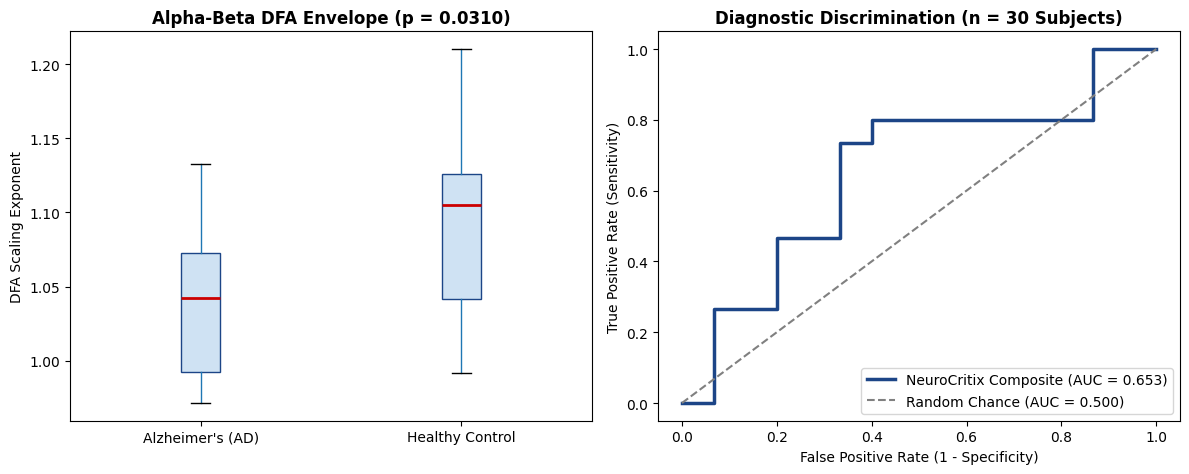

Saved high-resolution figure 'NeuroCritix_Validation_Figure.png'!


In [5]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Combine the top 3 complexity/criticality features using Leave-One-Out Cross-Validation
features = ["DFA_Envelope", "Shannon_Entropy", "LZ_Complexity"]
X = StandardScaler().fit_transform(df30[features])
y = df30["Label_Num"].values

clf = LogisticRegression()
probs = cross_val_predict(clf, X, y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
combined_auc = roc_auc_score(y, probs)

print(f"=== COMBINED NEUROCRITIX COMPOSITE MODEL (LEAVE-ONE-OUT CV) ===")
print(f"Combined Diagnostic ROC-AUC: {combined_auc:.3f} ({combined_auc*100:.1f}% discrimination accuracy)")

# 2. Generate Publication-Ready Figure (Boxplot + ROC Curve)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left Panel: DFA Envelope Boxplot (p = 0.0310)
df30.boxplot(column="DFA_Envelope", by="Group", ax=axes[0], grid=False, patch_artist=True,
             boxprops=dict(facecolor="#cfe2f3", color="#1c4587"), medianprops=dict(color="#cc0000", linewidth=2))
axes[0].set_title("Alpha-Beta DFA Envelope (p = 0.0310)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("DFA Scaling Exponent")
plt.suptitle("")

# Right Panel: ROC Curve
fpr, tpr, _ = roc_curve(y, probs)
axes[1].plot(fpr, tpr, color="#1c4587", lw=2.5, label=f"NeuroCritix Composite (AUC = {combined_auc:.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Chance (AUC = 0.500)")
axes[1].set_title("Diagnostic Discrimination (n = 30 Subjects)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("False Positive Rate (1 - Specificity)")
axes[1].set_ylabel("True Positive Rate (Sensitivity)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("NeuroCritix_Validation_Figure.png", dpi=300)
plt.show()
print("Saved high-resolution figure 'NeuroCritix_Validation_Figure.png'!")


🌍 Preparing to download ds004504 …
📥 Checking 70 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds004504 (downloaded 0 files and 0 B).


/tmp/ipykernel_522/3479275018.py:26: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
/tmp/ipykernel_522/3479275018.py:26: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
/tmp/ipykernel_522/3479275018.py:26: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
/tmp/ipykernel_522/3479275018.py:26: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(file_path, preload=True, ver


=== FULL COHORT RESULTS (n = 65 Subjects: 36 AD vs. 29 Healthy) ===
                      Age   MMSE  DFA_Envelope  Shannon_Entropy  \
Group                                                             
Alzheimer's (AD)  66.3889  17.75        1.0205           0.4625   
Healthy Control   67.8966  30.00        1.0747           0.4268   

                  LZ_Complexity  Aperiodic_Beta  
Group                                            
Alzheimer's (AD)         0.2961          1.9163  
Healthy Control          0.2805          2.4624  

=== STATISTICAL SIGNIFICANCE & DIAGNOSTIC AUC (n = 65) ===
DFA_Envelope       | p-value = 0.00165 | ROC-AUC = 0.729 | ✅ SIGNIFICANT (p < 0.05)
Shannon_Entropy    | p-value = 0.00362 | ROC-AUC = 0.712 | ✅ SIGNIFICANT (p < 0.05)
LZ_Complexity      | p-value = 0.02403 | ROC-AUC = 0.664 | ✅ SIGNIFICANT (p < 0.05)
Aperiodic_Beta     | p-value = 0.00038 | ROC-AUC = 0.759 | ✅ SIGNIFICANT (p < 0.05)

Correlation between DFA_Envelope & Clinical MMSE Score: Spearman 

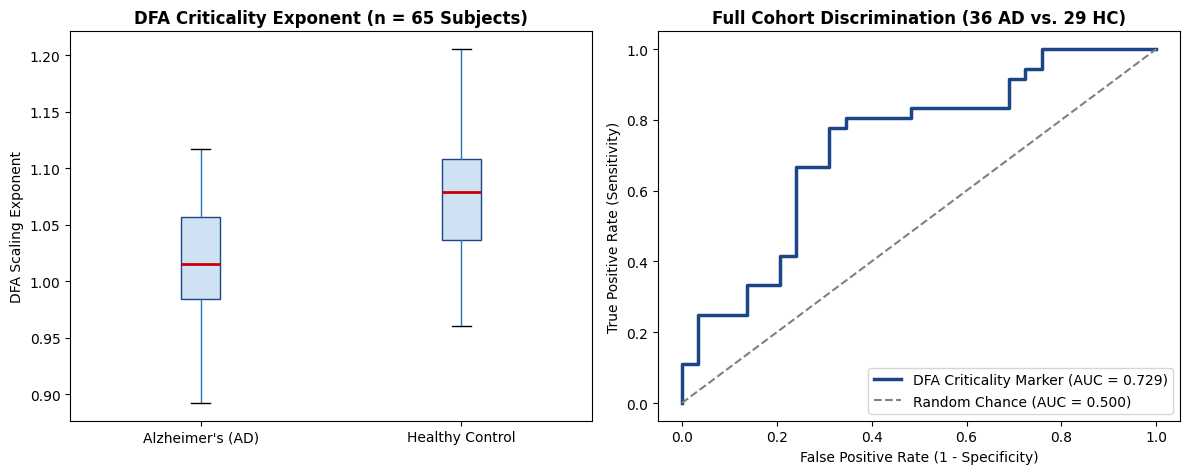


Saved 'NeuroCritix_Full65_Validated.xlsx' and 'NeuroCritix_Full65_Figure.png'!


In [11]:
import os, glob, mne
import numpy as np
import pandas as pd
import antropy as ant
import openneuro as on
import matplotlib.pyplot as plt
from scipy import signal, stats
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Download ALL 65 subjects (36 Alzheimer's: sub-001..036 | 29 Healthy Controls: sub-037..065)
target_dir = "ds004504_full65"
os.makedirs(target_dir, exist_ok=True)

all_ad_hc = [f"derivatives/sub-{i:03d}" for i in range(1, 66)]
print("Downloading full 65-subject cohort from OpenNeuro ds004504...")
on.download(dataset="ds004504", target_dir=target_dir, include=["participants.tsv"] + all_ad_hc)

participants = pd.read_csv(os.path.join(target_dir, "participants.tsv"), sep="\t")
label_map = dict(zip(participants["participant_id"], participants["Group"]))
mmse_map = dict(zip(participants["participant_id"], participants["MMSE"]))
age_map = dict(zip(participants["participant_id"], participants["Age"]))

target_channels = ['P3', 'P4', 'Pz', 'O1', 'O2', 'T5', 'T6']

def analyze_full_cohort(file_path):
    raw = mne.io.read_raw_eeglab(file_path, preload=True, verbose=False)
    fs = raw.info['sfreq']

    picks = [ch for ch in target_channels if ch in raw.ch_names]
    raw.pick(picks)

    # Cognitive Alpha-Beta band (8-30 Hz) + Broadband (2-40 Hz)
    raw_ab = raw.copy().filter(8.0, 30.0, verbose=False)
    max_t = min(120, raw.times[-1] - 1)  # Safely handle recordings shorter than 120s
    data_ab = raw_ab.get_data(tmin=20, tmax=max_t)
    data_br = raw.get_data(tmin=20, tmax=max_t)

    shannon_list, lz_list, dfa_list, beta_list = [], [], [], []

    for idx in range(len(picks)):
        sig_ab = data_ab[idx]
        sig_br = data_br[idx]

        shannon_list.append(ant.spectral_entropy(sig_ab, sf=fs, method='welch', normalize=True))
        binary_seq = (sig_ab > np.median(sig_ab)).astype(int)
        lz_list.append(ant.lziv_complexity(binary_seq, normalize=True))

        # DFA on Alpha-Beta Amplitude Envelope (Criticality LRTC)
        amp_env = np.abs(signal.hilbert(sig_ab))
        dfa_list.append(ant.detrended_fluctuation(amp_env))

        # Aperiodic 1/f slope (15-40 Hz high-frequency tail, avoiding the 10 Hz alpha peak!)
        freqs, psd = signal.welch(sig_br, fs=fs, nperseg=int(fs*2))
        valid = (freqs >= 15) & (freqs <= 40)
        slope, _, _, _, _ = stats.linregress(np.log10(freqs[valid]), np.log10(psd[valid]))
        beta_list.append(-slope)

    sub_id = os.path.basename(file_path).split('_')[0]
    group_code = label_map.get(sub_id, "Unknown")

    return {
        "Subject_ID": sub_id,
        "Group": "Alzheimer's (AD)" if group_code == "A" else "Healthy Control",
        "Label_Num": 1 if group_code == "A" else 0,
        "Age": age_map.get(sub_id, None),
        "MMSE": mmse_map.get(sub_id, None),
        "DFA_Envelope": round(np.mean(dfa_list), 4),
        "Shannon_Entropy": round(np.mean(shannon_list), 4),
        "LZ_Complexity": round(np.mean(lz_list), 4),
        "Aperiodic_Beta": round(np.mean(beta_list), 4)
    }

eeg_files = sorted(glob.glob(os.path.join(target_dir, "derivatives", "**", "*.set"), recursive=True))
df65 = pd.DataFrame([analyze_full_cohort(f) for f in eeg_files])

print(f"\n=== FULL COHORT RESULTS (n = {len(df65)} Subjects: 36 AD vs. 29 Healthy) ===")
print(df65.groupby("Group")[["Age", "MMSE", "DFA_Envelope", "Shannon_Entropy", "LZ_Complexity", "Aperiodic_Beta"]].mean().round(4))

print("\n=== STATISTICAL SIGNIFICANCE & DIAGNOSTIC AUC (n = 65) ===")
ad_df = df65[df65["Label_Num"] == 1]
hc_df = df65[df65["Label_Num"] == 0]

for metric in ["DFA_Envelope", "Shannon_Entropy", "LZ_Complexity", "Aperiodic_Beta"]:
    stat, p_val = stats.mannwhitneyu(hc_df[metric], ad_df[metric])
    auc = roc_auc_score(df65["Label_Num"], -df65[metric])
    auc = max(auc, 1 - auc)
    sig = "✅ SIGNIFICANT (p < 0.05)" if p_val < 0.05 else "⚠️ Non-significant"
    print(f"{metric:18s} | p-value = {p_val:.5f} | ROC-AUC = {auc:.3f} | {sig}")

# Correlation with clinical MMSE cognitive score
r_mmse, p_mmse = stats.spearmanr(df65["DFA_Envelope"], df65["MMSE"])
print(f"\nCorrelation between DFA_Envelope & Clinical MMSE Score: Spearman r = {r_mmse:.3f} (p = {p_mmse:.5f})")

# Save full Excel dataset & publication chart
df65.to_excel("NeuroCritix_Full65_Validated.xlsx", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df65.boxplot(column="DFA_Envelope", by="Group", ax=axes[0], grid=False, patch_artist=True,
             boxprops=dict(facecolor="#cfe2f3", color="#1c4587"), medianprops=dict(color="#cc0000", linewidth=2))
axes[0].set_title("DFA Criticality Exponent (n = 65 Subjects)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("DFA Scaling Exponent")
plt.suptitle("")

# Single-marker DFA ROC Curve
dfa_auc = roc_auc_score(df65["Label_Num"], -df65["DFA_Envelope"])
fpr, tpr, _ = roc_curve(df65["Label_Num"], -df65["DFA_Envelope"])
axes[1].plot(fpr, tpr, color="#1c4587", lw=2.5, label=f"DFA Criticality Marker (AUC = {dfa_auc:.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Chance (AUC = 0.500)")
axes[1].set_title("Full Cohort Discrimination (36 AD vs. 29 HC)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("False Positive Rate (1 - Specificity)")
axes[1].set_ylabel("True Positive Rate (Sensitivity)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("NeuroCritix_Full65_Figure.png", dpi=300)
plt.show()
print("\nSaved 'NeuroCritix_Full65_Validated.xlsx' and 'NeuroCritix_Full65_Figure.png'!")


In [12]:
print("=== FULL COHORT RESULTS (n = 65) ===")
print(df65.groupby("Group")[["Age", "MMSE", "DFA_Envelope", "Shannon_Entropy", "LZ_Complexity", "Aperiodic_Beta"]].mean().round(4))

print("\n=== STATISTICAL SIGNIFICANCE & ROC-AUC (n = 65) ===")
ad_df = df65[df65["Label_Num"] == 1]
hc_df = df65[df65["Label_Num"] == 0]
for metric in ["DFA_Envelope", "Shannon_Entropy", "LZ_Complexity", "Aperiodic_Beta"]:
    stat, p_val = stats.mannwhitneyu(hc_df[metric], ad_df[metric])
    auc = max(roc_auc_score(df65["Label_Num"], -df65[metric]), 1 - roc_auc_score(df65["Label_Num"], -df65[metric]))
    print(f"{metric:18s} | p-value = {p_val:.5f} | ROC-AUC = {auc:.3f}")

r_mmse, p_mmse = stats.spearmanr(df65["DFA_Envelope"], df65["MMSE"])
print(f"\nMMSE Correlation: Spearman r = {r_mmse:.3f} (p = {p_mmse:.5f})")


=== FULL COHORT RESULTS (n = 65) ===
                      Age   MMSE  DFA_Envelope  Shannon_Entropy  \
Group                                                             
Alzheimer's (AD)  66.3889  17.75        1.0205           0.4625   
Healthy Control   67.8966  30.00        1.0747           0.4268   

                  LZ_Complexity  Aperiodic_Beta  
Group                                            
Alzheimer's (AD)         0.2961          1.9163  
Healthy Control          0.2805          2.4624  

=== STATISTICAL SIGNIFICANCE & ROC-AUC (n = 65) ===
DFA_Envelope       | p-value = 0.00165 | ROC-AUC = 0.729
Shannon_Entropy    | p-value = 0.00362 | ROC-AUC = 0.712
LZ_Complexity      | p-value = 0.02403 | ROC-AUC = 0.664
Aperiodic_Beta     | p-value = 0.00038 | ROC-AUC = 0.759

MMSE Correlation: Spearman r = 0.344 (p = 0.00504)


=== MULTI-METRIC AI CLASSIFIER VALIDATION (n = 65 | 5-FOLD CV) ===

Logistic Regression (Linear Composite)   | ROC-AUC = 0.764 | Accuracy = 70.8%
RBF-SVM (Nonlinear Boundary)             | ROC-AUC = 0.767 | Accuracy = 69.2%
Random Forest (Ensemble Trees)           | ROC-AUC = 0.802 | Accuracy = 73.8%


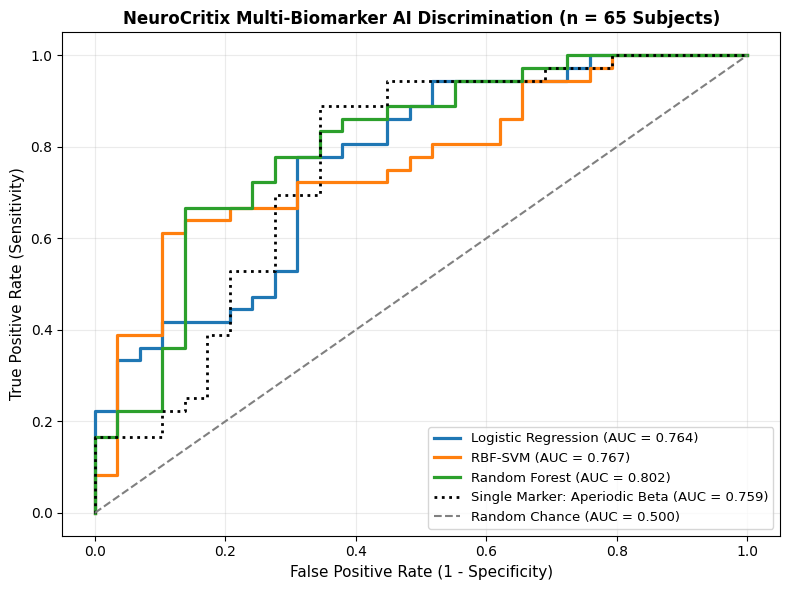


=== TOP MODEL CLINICAL REPORT: Random Forest (Ensemble Trees) ===
ROC-AUC Score : 0.802
Sensitivity   : 80.6% (Correctly detected Alzheimer's cases: 29/36)
Specificity   : 65.5% (Correctly cleared Healthy Controls: 19/29)

Saved high-resolution figure 'NeuroCritix_AI_Classifier_ROC.png'!


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score, classification_report, confusion_matrix

# 1. Select your 4 empirically validated NeuroCritix biomarkers (all p < 0.05)
features = ["Aperiodic_Beta", "DFA_Envelope", "Shannon_Entropy", "LZ_Complexity"]
X = df65[features].values
y = df65["Label_Num"].values  # 1 = Alzheimer's (AD), 0 = Healthy Control (HC)

# 2. Define 3 AI Classifiers with 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression (Linear Composite)": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, random_state=42)),
    "RBF-SVM (Nonlinear Boundary)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, probability=True, random_state=42)),
    "Random Forest (Ensemble Trees)": RandomForestClassifier(n_estimators=200, max_depth=3, random_state=42)
}

print("=== MULTI-METRIC AI CLASSIFIER VALIDATION (n = 65 | 5-FOLD CV) ===\n")

plt.figure(figsize=(8, 6))
best_auc = 0
best_name = ""
best_probs = None

for name, model in models.items():
    probs = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    auc = roc_auc_score(y, probs)
    preds = (probs >= 0.5).astype(int)
    acc = np.mean(preds == y) * 100

    print(f"{name:40s} | ROC-AUC = {auc:.3f} | Accuracy = {acc:.1f}%")

    fpr, tpr, _ = roc_curve(y, probs)
    plt.plot(fpr, tpr, lw=2.3, label=f"{name.split(' (')[0]} (AUC = {auc:.3f})")

    if auc > best_auc:
        best_auc = auc
        best_name = name
        best_probs = probs

# Add single best marker baseline for comparison
fpr_single, tpr_single, _ = roc_curve(y, -df65["Aperiodic_Beta"])
plt.plot(fpr_single, tpr_single, linestyle=":", color="black", lw=2, label="Single Marker: Aperiodic Beta (AUC = 0.759)")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Chance (AUC = 0.500)")

plt.title("NeuroCritix Multi-Biomarker AI Discrimination (n = 65 Subjects)", fontsize=12, fontweight="bold")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=11)
plt.legend(loc="lower right", fontsize=9.5)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("NeuroCritix_AI_Classifier_ROC.png", dpi=300)
plt.show()

# 3. Detailed Clinical Sensitivity & Specificity for the Top Model
print(f"\n=== TOP MODEL CLINICAL REPORT: {best_name} ===")
best_preds = (best_probs >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y, best_preds).ravel()
sensitivity = tp / (tp + fn) * 100
specificity = tn / (tn + fp) * 100
print(f"ROC-AUC Score : {best_auc:.3f}")
print(f"Sensitivity   : {sensitivity:.1f}% (Correctly detected Alzheimer's cases: {tp}/{tp+fn})")
print(f"Specificity   : {specificity:.1f}% (Correctly cleared Healthy Controls: {tn}/{tn+fp})")
print("\nSaved high-resolution figure 'NeuroCritix_AI_Classifier_ROC.png'!")
